# Material de aula - FACENS - Redes Neurais e Deep Learning


## <center> Laboratório 3 - Tensor Flow: Regressão Logística </center>

In [4]:
#CÉLULA TF-LIB-01
import tensorflow as tf
import pandas as pd
import numpy as np
import time
from sklearn.datasets import load_iris
from sklearn.cross_validation import train_test_split
import matplotlib.pyplot as plt

### 1 - Carregue o dataset e separe os conjuntos de treino e teste

In [5]:
#CÉLULA TF-LIB-02


### 2 - Defina os placeholders X e Y

In [6]:
#CÉLULA TF-LIB-02
# No dataset iris, são usadas '4' features.
numFeatures = 

# No dataset iris dataset, o numero de casses é 3.
numLabels = 


# Placeholders
# 'None' significa que o TensorFlow não espera um valor fixo para esta dimensão


### 3 - Crie o vetor de pesos e bias

In [7]:
#CÉLULA TF-LIB-03
W = 
b = 

Instructions for updating:
Colocations handled automatically by placer.


### 4 -  Faça a inicialização das matrizes de pesos e bias com valores aleatórios

In [8]:
#CÉLULA TF-LIB-04
weights = tf.Variable(tf.random_normal([numFeatures,numLabels],
                                       mean=0,
                                       stddev=0.01,
                                       name="weights"))

bias = tf.Variable(tf.random_normal([1,numLabels],
                                    mean=0,
                                    stddev=0.01,
                                    name="bias"))

### 5 -Defina o modelo da rede

$$
ŷ =sigmoid(WX+b)
$$


In [9]:
#CÉLULA TF-LIB-05
apply_weights_OP = tf.matmul(X, weights,     name="apply_weights")
add_bias_OP = tf.add(apply_weights_OP, bias, name="add_bias") 
activation_OP = tf.nn.sigmoid(add_bias_OP,   name="activation")

### 6 - Defina os parametros de treinamento

In [10]:
#CÉLULA TF-LIB-07
numEpochs = 700

# Definindo a taxa de aprendizado
learningRate = tf.train.exponential_decay(learning_rate=0.0008,
                                          global_step= 1,
                                          decay_steps=trainX.shape[0],
                                          decay_rate= 0.95,
                                          staircase=True)

### 7 - Defina a função de custo - Mean Squared Error

In [11]:
#CÉLULA TF-LIB-08

#Defina o otimizador


### 8 - Inicialize as variaveis e execute a sessão de inicialização

In [13]:
#CÉLULA TF-LIB-09
sess = tf.Session()
init_OP = tf.global_variables_initializer()
sess.run(init_OP)

In [14]:
# argmax(activation_OP, 1) returns the label with the most probability
# argmax(yGold, 1) is the correct label
correct_predictions_OP = tf.equal(tf.argmax(activation_OP,1),tf.argmax(yGold,1))

# If every false prediction is 0 and every true prediction is 1, the average returns us the accuracy
accuracy_OP = tf.reduce_mean(tf.cast(correct_predictions_OP, "float"))

# Summary op for regression output
activation_summary_OP = tf.summary.histogram("output", activation_OP)

# Summary op for accuracy
accuracy_summary_OP = tf.summary.scalar("accuracy", accuracy_OP)

# Summary op for cost
cost_summary_OP = tf.summary.scalar("cost", cost_OP)

# Summary ops to check how variables (W, b) are updating after each iteration
weightSummary = tf.summary.histogram("weights", weights.eval(session=sess))
biasSummary = tf.summary.histogram("biases", bias.eval(session=sess))

# Merge all summaries
merged = tf.summary.merge([activation_summary_OP, accuracy_summary_OP, cost_summary_OP, weightSummary, biasSummary])

# Summary writer
writer = tf.summary.FileWriter("summary_logs", sess.graph)

### 9 - Agora rode o treinamento de ajuste

In [15]:
#CÉLULA TF-LIB-10

# Initialize reporting variables
cost = 0
diff = 1
epoch_values = []
accuracy_values = []
cost_values = []

# Training epochs
for i in range(numEpochs):
    if i > 1 and diff < .0001:
        print("change in cost %g; convergence."%diff)
        break
    else:
        # IMPLEMENTE CODIGO AQUI
        
        
        # Imprima o status
        if i % 10 == 0:
            # Add epoch to epoch_values
            epoch_values.append(i)
            # Generate accuracy stats on test data
            train_accuracy, newCost = sess.run([accuracy_OP, cost_OP], feed_dict={X: trainX, yGold: trainY})
            # Add accuracy to live graphing variable
            accuracy_values.append(train_accuracy)
            # Add cost to live graphing variable
            cost_values.append(newCost)
            # Re-assign values for variables
            diff = abs(newCost - cost)
            cost = newCost

            #generate print statements
            print("step %d, training accuracy %g, cost %g, change in cost %g"%(i, train_accuracy, newCost, diff))


# How well do we perform on held-out test data?
print("final accuracy on test set: %s" %str(sess.run(accuracy_OP, 
                                                     feed_dict={X: testX, 
                                                                yGold: testY})))

step 0, training accuracy 0.333333, cost 34.4598, change in cost 34.4598
step 10, training accuracy 0.555556, cost 30.1282, change in cost 4.33156
step 20, training accuracy 0.646465, cost 28.1882, change in cost 1.93999
step 30, training accuracy 0.646465, cost 26.5483, change in cost 1.63988
step 40, training accuracy 0.646465, cost 25.1837, change in cost 1.36467
step 50, training accuracy 0.646465, cost 24.0548, change in cost 1.1289
step 60, training accuracy 0.646465, cost 23.1194, change in cost 0.935394
step 70, training accuracy 0.646465, cost 22.3395, change in cost 0.779871
step 80, training accuracy 0.646465, cost 21.6837, change in cost 0.655838
step 90, training accuracy 0.646465, cost 21.1268, change in cost 0.556902
step 100, training accuracy 0.656566, cost 20.6491, change in cost 0.477631
step 110, training accuracy 0.666667, cost 20.2355, change in cost 0.41367
step 120, training accuracy 0.666667, cost 19.8738, change in cost 0.361652
step 130, training accuracy 0.6

### 10 - O código abaixo plota o gráfico dos dados e da reta ajustada

C:\Program Files (x86)\Microsoft Visual Studio\Shared\Anaconda3_64\lib\site-packages\numpy\core\fromnumeric.py:3118: RuntimeWarning: Mean of empty slice.
  out=out, **kwargs)
C:\Program Files (x86)\Microsoft Visual Studio\Shared\Anaconda3_64\lib\site-packages\numpy\core\_methods.py:85: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


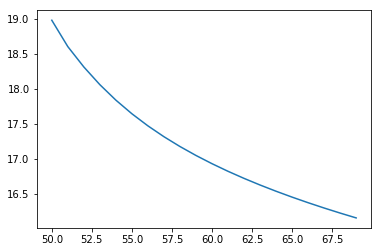

In [16]:
#CÉLULA TF-LIB-11
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
plt.plot([np.mean(cost_values[i-50:i]) for i in range(len(cost_values))])
plt.show()